# Praktikum 2 — Konsep Stasioneritas: Uji ADF/KPSS dan Penanganan Non-Stasioneritas

---

Nama: Safina Zahra  
NIM: 52250033  
Mata kuliah: Analisis Runtun Waktu  
Program studi: Sains Data, Institut Teknologi Sains Bandung  
Dosen pengampu: Bakti Siregar, S.Si., M.Sc  
Materi: Bab 2 — Konsep Stasioneritas (Latihan 2.1, 2.2, 2.3)

---


## Gambaran umum

**Tujuan.** Praktikum ini melatih tiga hal: (1) menguji stasioneritas deret waktu dengan ADF dan KPSS, lalu menangani deret yang belum stasioner lewat differencing atau transformasi; (2) mengukur seberapa andal uji KPSS lewat simulasi Monte Carlo; (3) memeriksa apakah hasil uji sejalan dengan pola musiman pada data suhu Melbourne.

**Alur kerja.**
1. Membuat fungsi `uji_stasioner` dan mencobanya pada enam deret simulasi.
2. Latihan 2.1: menguji dan menangani data Tugas 1, yaitu inflasi bulanan Indonesia (BPS).
3. Latihan 2.2: simulasi ukuran dan kuasa uji KPSS.
4. Latihan 2.3: uji stasioneritas suhu minimum harian Melbourne.

**Pegangan membaca hasil.** ADF punya H₀ "ada akar unit" (non-stasioner), sedangkan KPSS punya H₀ "stasioner". Karena arah hipotesisnya berlawanan, keduanya dipakai bersama. Setiap bagian diakhiri kotak *Interpretasi*.


## 0. Persiapan

In [ ]:
import os
import warnings
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})

SEED = 52250033                      # NIM, supaya simulasi bisa diulang
BRN = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/'

In [ ]:
# Data Tugas 1: inflasi bulanan Indonesia (berkas yang sama dengan Praktikum 1)
FILE = 'tingkat-inflasi-bulan-ke-bulan-gabungan-90-kota-seluruh-indonesia.csv'
if not os.path.exists(FILE):                     # di Colab: unggah berkas CSV-nya dulu
    from google.colab import files
    files.upload()

mentah = pd.read_csv(FILE, sep=';')
nama_bulan = {'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4, 'Mei': 5, 'Juni': 6,
              'Juli': 7, 'Agustus': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12}
tgl = pd.to_datetime(dict(year=mentah['tahun'], month=mentah['bulan'].map(nama_bulan), day=1))
inflasi = pd.Series(mentah['tingkat_inflasi_bulanan'].values, index=pd.DatetimeIndex(tgl, freq='MS'),
                    name='inflasi_bulanan_persen')

# Data pembanding untuk Latihan 2.3
suhu_melb = pd.read_csv(BRN + 'daily-min-temperatures.csv', parse_dates=['Date'], index_col='Date')['Temp']
print('inflasi :', len(inflasi), 'bulan,', inflasi.index[0].date(), 'sampai', inflasi.index[-1].date())
print('suhu    :', len(suhu_melb), 'hari,', suhu_melb.index[0].date(), 'sampai', suhu_melb.index[-1].date())

inflasi : 231 bulan, 2006-01-01 sampai 2025-03-01
suhu    : 3650 hari, 1981-01-01 sampai 1990-12-31


## 1. Alat uji: fungsi `uji_stasioner` dan galeri simulasi
Fungsi menjalankan ADF (H₀: ada akar unit) dan KPSS (H₀: stasioner) sekaligus, lalu menyimpulkan dengan aturan gabungan dari Tabel 2.5 pada buku.

In [ ]:
@dataclass
class HasilStasioner:
    nama: str
    adf_stat: float
    adf_p: float
    kpss_stat: float
    kpss_p: float
    kesimpulan: str

def uji_stasioner(y, nama='', alpha=0.05, regresi='c'):
    """Jalankan ADF dan KPSS, kembalikan hasil terstruktur (tidak mencetak apa pun)."""
    y = pd.Series(y).dropna()
    if len(y) < 20:
        raise ValueError(f'deret terlalu pendek untuk uji ({len(y)} < 20)')
    adf = adfuller(y, regression=regresi, autolag='AIC')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # KPSS memperingatkan bila p di luar tabel (0,01-0,10)
        kp = kpss(y, regression=regresi, nlags='auto')
    tolak_adf, tolak_kpss = adf[1] < alpha, kp[1] < alpha
    kesimpulan = {(True, False): 'stasioner',
                  (False, True): 'non-stasioner (akar unit)',
                  (True, True): 'stasioner terhadap tren',
                  (False, False): 'tidak meyakinkan'}[(tolak_adf, tolak_kpss)]
    return HasilStasioner(nama, round(adf[0], 3), round(adf[1], 4), round(kp[0], 3), round(kp[1], 4), kesimpulan)

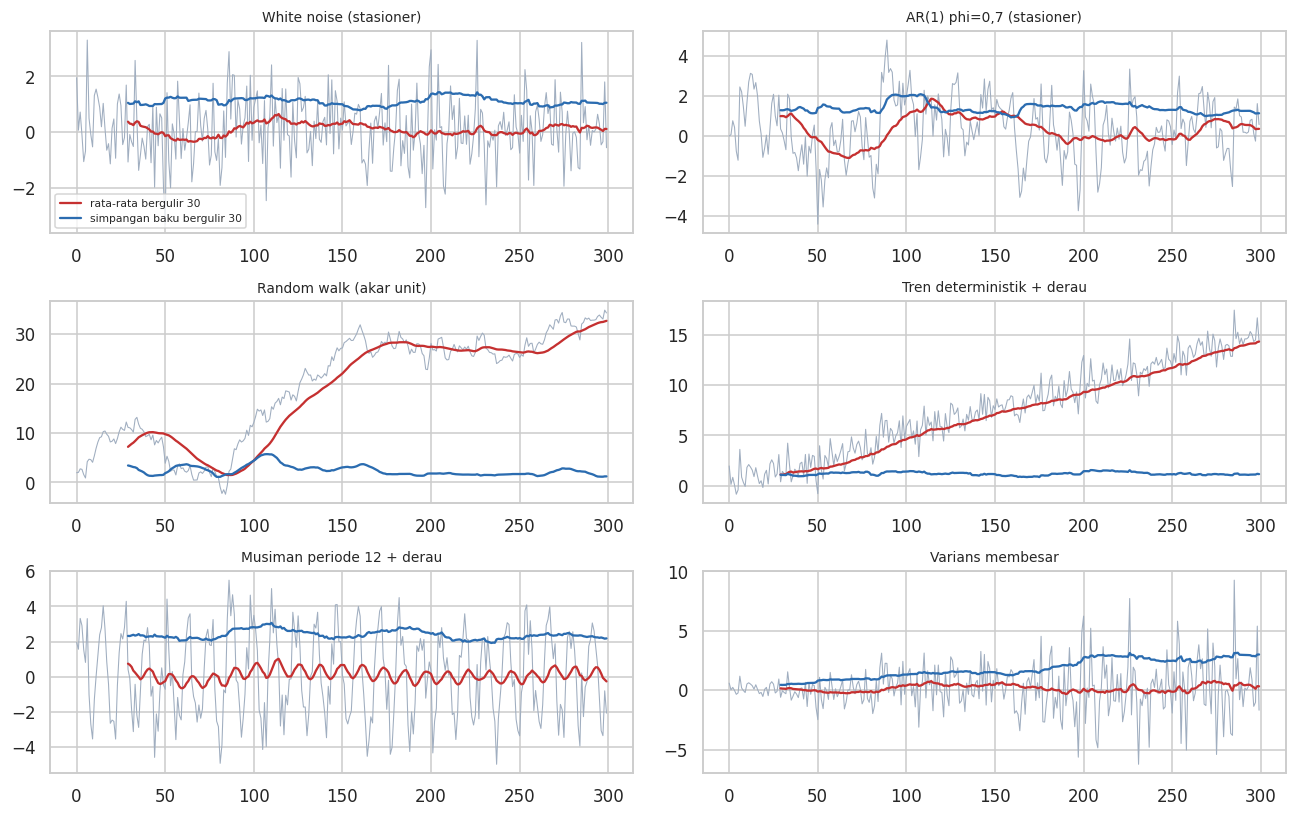

,adf_stat,adf_p,kpss_stat,kpss_p,kesimpulan
nama,,,,,
White noise (stasioner),-17.015,0.0000,0.079,0.10,stasioner
"AR(1) phi=0,7 (stasioner)",-7.417,0.0000,0.105,0.10,stasioner
Random walk (akar unit),-1.092,0.7184,2.394,0.01,non-stasioner (akar unit)
Tren deterministik + derau,0.374,0.9805,2.809,0.01,non-stasioner (akar unit)
Musiman periode 12 + derau,-3.780,0.0031,0.045,0.10,stasioner
Varians membesar,-9.477,0.0000,0.081,0.10,stasioner
"Tren deterministik, uji regresi=""ct""",-16.989,0.0000,0.064,0.10,stasioner


In [ ]:
rng = np.random.default_rng(SEED)
n = 300
e = rng.normal(size=n)
t = np.arange(n)

def ar1(phi, e):
    y = np.zeros_like(e)
    for i in range(1, len(e)):
        y[i] = phi * y[i - 1] + e[i]
    return y

galeri = {
    'White noise (stasioner)': e,
    'AR(1) phi=0,7 (stasioner)': ar1(0.7, e),
    'Random walk (akar unit)': np.cumsum(e),
    'Tren deterministik + derau': 0.05 * t + e,
    'Musiman periode 12 + derau': 3 * np.sin(2 * np.pi * t / 12) + e,
    'Varians membesar': e * np.linspace(0.3, 3, n),
}
fig, axs = plt.subplots(3, 2, figsize=(12, 7.5))
for ax, (judul, y) in zip(axs.ravel(), galeri.items()):
    s = pd.Series(y)
    ax.plot(y, lw=.7, color='#a0aec0')
    ax.plot(s.rolling(30).mean(), color='#c53030', lw=1.5, label='rata-rata bergulir 30')
    ax.plot(s.rolling(30).std(), color='#2b6cb0', lw=1.5, label='simpangan baku bergulir 30')
    ax.set_title(judul, fontsize=9)
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

tabel = [uji_stasioner(y, j) for j, y in galeri.items()]
tabel.append(uji_stasioner(galeri['Tren deterministik + derau'], 'Tren deterministik, uji regresi="ct"', regresi='ct'))
pd.DataFrame(tabel).set_index('nama')

> **Interpretasi.** Fungsi `uji_stasioner` bekerja sesuai harapan pada kasus yang jelas. *White noise* dan AR(1) dengan φ = 0,7 stasioner (ADF p = 0,0000 dan KPSS p = 0,10), sedangkan *random walk* non-stasioner (ADF p = 0,7184 dan KPSS p = 0,01). Ada tiga hal yang perlu diperhatikan:
> - Deret **tren deterministik** terbaca "akar unit" bila diuji dengan konstanta saja (ADF p = 0,9805), tetapi menjadi stasioner setelah komponen tren dimasukkan (`regresi='ct'`, ADF statistik −16,989). Jadi bentuk uji harus sesuai bentuk deret.
> - Deret **musiman** dan **varians membesar** tetap dinyatakan stasioner oleh kedua uji, padahal secara visual jelas berpola. ADF dan KPSS terutama memeriksa rata-rata, bukan varians atau musiman.
> - Karena itu pemeriksaan visual (garis merah dan biru pada grafik) tetap wajib dan tidak bisa digantikan uji formal.


## 2. Latihan 2.1 — Uji stasioneritas pada data Tugas 1 (inflasi bulanan)

### 2.1.1 Langkah 1: lihat dulu secara visual

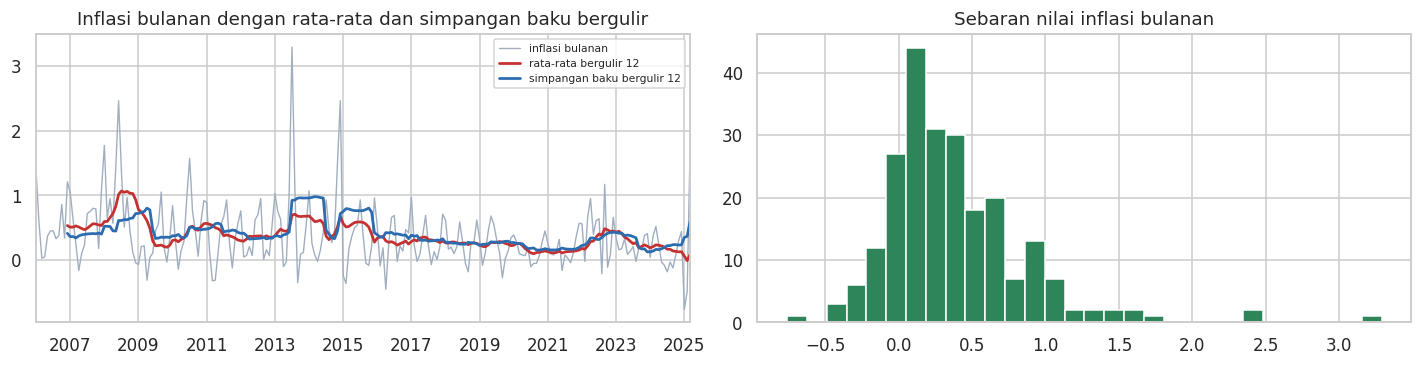

rata-rata paruh 1 vs paruh 2 : 0.518 vs 0.235
std paruh 1 vs paruh 2       : 0.581 vs 0.332


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
inflasi.plot(ax=ax[0], lw=.9, color='#a0aec0', label='inflasi bulanan')
inflasi.rolling(12).mean().plot(ax=ax[0], lw=1.8, color='#c53030', label='rata-rata bergulir 12')
inflasi.rolling(12).std().plot(ax=ax[0], lw=1.8, color='#2b6cb0', label='simpangan baku bergulir 12')
ax[0].legend(fontsize=7); ax[0].set_title('Inflasi bulanan dengan rata-rata dan simpangan baku bergulir')
ax[1].hist(inflasi, bins=30, color='#2f855a'); ax[1].set_title('Sebaran nilai inflasi bulanan')
plt.tight_layout(); plt.show()

paruh = len(inflasi) // 2
print('rata-rata paruh 1 vs paruh 2 :', round(inflasi.iloc[:paruh].mean(), 3), 'vs', round(inflasi.iloc[paruh:].mean(), 3))
print('std paruh 1 vs paruh 2       :', round(inflasi.iloc[:paruh].std(), 3), 'vs', round(inflasi.iloc[paruh:].std(), 3))

> **Interpretasi.** Secara visual inflasi bulanan **belum terlihat stasioner penuh**. Rata-rata bergulir (garis merah) naik tajam sekitar 2008 lalu turun dan bertahan rendah setelah 2015, dan simpangan baku bergulir (garis biru) ikut mengecil. Angkanya mendukung: rata-rata paruh pertama data 0,518% dibanding 0,235% di paruh kedua, dan simpangan baku 0,581 dibanding 0,332. Histogramnya miring ke kanan dengan beberapa nilai ekstrem di atas 2%, yaitu kejutan harga yang sudah kita lihat di Praktikum 1.


### 2.1.2 Langkah 2: uji ADF dan KPSS pada data asli

In [ ]:
hasil_level = [uji_stasioner(inflasi, 'inflasi (level), konstanta', regresi='c'),
               uji_stasioner(inflasi, 'inflasi (level), konstanta + tren', regresi='ct')]
pd.DataFrame(hasil_level).set_index('nama')

,adf_stat,adf_p,kpss_stat,kpss_p,kesimpulan
nama,,,,,
"inflasi (level), konstanta",-3.144,0.0235,1.811,0.01,stasioner terhadap tren
"inflasi (level), konstanta + tren",-4.088,0.0066,0.036,0.10,stasioner


> **Interpretasi.** Hasil uji pada data asli:
> - Dengan konstanta saja: ADF menolak akar unit (statistik −3,144; p = 0,0235) **dan** KPSS menolak stasioneritas (statistik 1,811; p = 0,01). Menurut aturan gabungan, ini kesimpulan "stasioner terhadap tren".
> - Dengan konstanta dan tren: ADF tetap menolak akar unit (p = 0,0066) dan KPSS tidak menolak (p = 0,10), sehingga deret dinyatakan stasioner.
>
> Artinya inflasi **tidak punya akar unit**: guncangan bersifat sementara dan inflasi kembali ke level tengahnya. Namun level tengah itu sendiri bergeser turun dari waktu ke waktu, itulah yang membuat KPSS menolak bila rata-rata dianggap tetap. Catatan teknis: p-value KPSS hanya dilaporkan dalam rentang 0,01 sampai 0,10, jadi angka 0,01 dan 0,10 berarti "paling kecil" dan "paling besar" yang bisa dilaporkan.


### 2.1.3 Langkah 3: transformasi dan uji ulang
Log tidak bisa dipakai karena ada nilai negatif. Pilihan yang tersisa adalah differencing biasa (menghapus pergeseran level) dan differencing musiman lag 12 (menghapus pola tahunan).

In [ ]:
tahap = {
    'asli': inflasi,
    'diff 1 (selisih biasa)': inflasi.diff(),
    'diff 12 (selisih musiman)': inflasi.diff(12),
    'diff 1 + diff 12': inflasi.diff(12).diff(),
}
tabel_tahap = pd.DataFrame([uji_stasioner(s, j) for j, s in tahap.items()]).set_index('nama')
tabel_tahap['std'] = [round(s.dropna().std(), 3) for s in tahap.values()]
tabel_tahap['autokorelasi lag 1'] = [round(s.dropna().autocorr(1), 3) for s in tahap.values()]
tabel_tahap['autokorelasi lag 12'] = [round(s.dropna().autocorr(12), 3) for s in tahap.values()]
tabel_tahap

,adf_stat,adf_p,kpss_stat,kpss_p,kesimpulan,std,autokorelasi lag 1,autokorelasi lag 12
nama,,,,,,,,
asli,-3.144,0.0235,1.811,0.0100,stasioner terhadap tren,0.492,0.394,0.295
diff 1 (selisih biasa),-8.085,0.0000,0.319,0.1000,stasioner,0.537,-0.098,0.275
diff 12 (selisih musiman),-7.746,0.0000,0.028,0.1000,stasioner,0.581,0.386,-0.489
diff 1 + diff 12,-7.663,0.0000,0.500,0.0417,stasioner terhadap tren,0.642,-0.222,-0.419


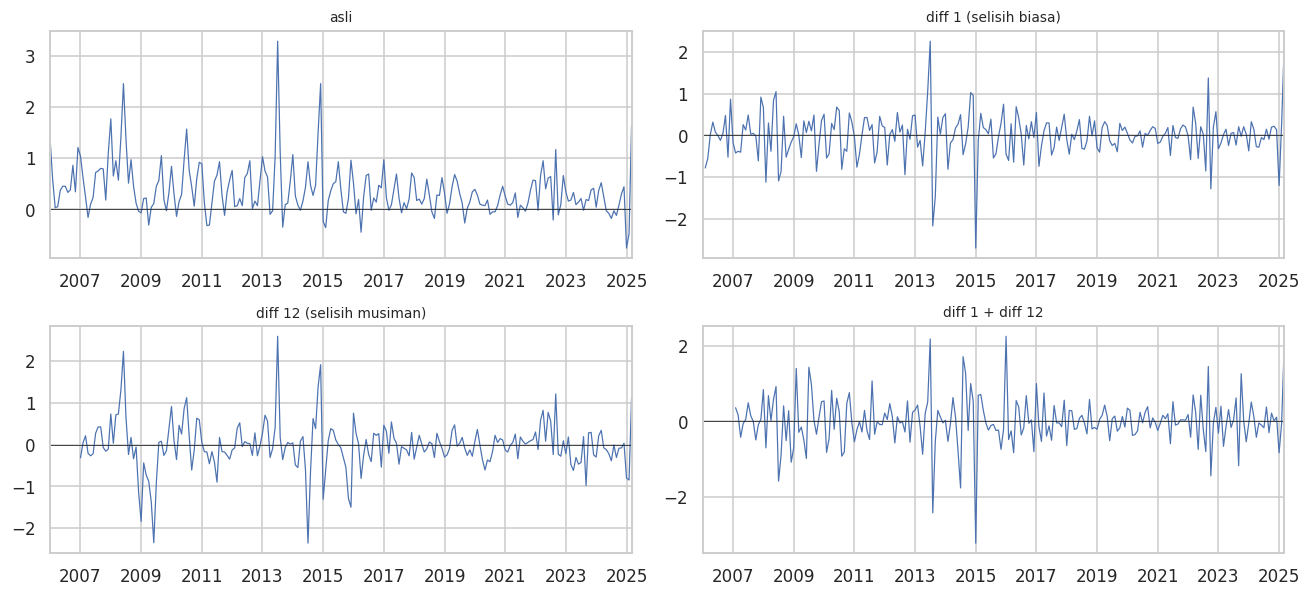

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 5.5))
for ax, (judul, s) in zip(axs.ravel(), tahap.items()):
    s.plot(ax=ax, lw=.8); ax.axhline(0, color='k', lw=.5); ax.set_title(judul, fontsize=9); ax.set_xlabel('')
plt.tight_layout(); plt.show()

### Jawaban Latihan 2.1 — Urutan langkah dan alasannya

| Tahap | Hasil ADF dan KPSS | Simpangan baku | Autokorelasi lag 1 | Autokorelasi lag 12 |
|---|---|---|---|---|
| Asli | ADF p = 0,0235; KPSS p = 0,01 (stasioner terhadap tren) | 0,492 | 0,394 | 0,295 |
| Selisih biasa (d = 1) | ADF p = 0,0000; KPSS p = 0,10 (**stasioner**) | 0,537 | −0,098 | 0,275 |
| Selisih musiman (lag 12) | ADF p = 0,0000; KPSS p = 0,10 (stasioner) | 0,581 | 0,386 | −0,489 |
| Selisih biasa + musiman | ADF p = 0,0000; KPSS p = 0,0417 (stasioner terhadap tren) | 0,642 | −0,222 | −0,419 |

**Langkah dan alasan.**
1. **Lihat grafik dulu.** Level dan variabilitas bergeser (rata-rata 0,518% menjadi 0,235%), jadi ada alasan curiga.
2. **Uji ADF dan KPSS.** Tidak ada akar unit, tetapi KPSS menolak karena level bergeser.
3. **Log tidak dipakai.** Data punya nilai negatif (minimum −0,76%), sehingga log tidak terdefinisi.
4. **Selisih biasa (d = 1) dipilih.** Hasilnya lolos kedua uji dengan jelas, sementara harganya kecil: simpangan baku hanya naik dari 0,492 ke 0,537 dan autokorelasi lag 1 hanya −0,098.
5. **Selisih musiman tidak dipakai.** Musimannya lemah (rata-rata bulanan hanya berkisar 0,12% sampai 0,70%), dan hasilnya menimbulkan autokorelasi lag 12 sebesar −0,489, tanda mendifferensiasi berlebihan.
6. **Kombinasi keduanya ditolak.** Simpangan baku naik ke 0,642, autokorelasi lag 1 menjadi −0,222, dan KPSS kembali menolak (p = 0,0417). Ini contoh *over-differencing* seperti dibahas pada Subbab 2.5.3 buku.

> **Interpretasi.** Deret yang dipakai untuk analisis ACF/PACF di Praktikum 4 adalah **selisih biasa dari inflasi bulanan** (d = 1). Prinsipnya memilih differencing sesedikit mungkin yang membuat deret stasioner. Alternatif yang masih masuk akal adalah memakai data asli, karena sudah stasioner terhadap tren. Keputusan akhir bisa diperkuat dengan melihat ACF/PACF pada praktikum berikutnya.


## 3. Latihan 2.2 — Ukuran dan kuasa uji KPSS (simulasi Monte Carlo)
Fungsi `tingkat_tolak` pada buku dimodifikasi supaya memakai KPSS. Pada KPSS hipotesis nolnya stasioner, jadi **white noise = H₀ benar** (tingkat tolak seharusnya sekitar 5%) dan **random walk = H₀ salah** (tingkat tolak makin tinggi makin baik, ini kuasa uji).

In [ ]:
def tingkat_tolak_kpss(pembangkit, n_rep=500, n=100, alpha=0.05, regresi='c'):
    """Proporsi replikasi yang menolak H0 KPSS (H0: deret stasioner)."""
    tolak = 0
    for i in range(n_rep):
        y = pembangkit(np.random.default_rng(i), n)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            tolak += kpss(y, regression=regresi, nlags='auto')[1] < alpha
    return tolak / n_rep

skenario = {
    'white noise (H0 benar)': lambda g, n: g.normal(size=n),
    'random walk (H0 salah)': lambda g, n: np.cumsum(g.normal(size=n)),
}
hasil_kpss = {nama: tingkat_tolak_kpss(f, n=100) for nama, f in skenario.items()}
for nama, nilai in hasil_kpss.items():
    print(f'n = 100 | {nama:<24} -> tolak H0 KPSS = {nilai:.1%}')

n = 100 | white noise (H0 benar)   -> tolak H0 KPSS = 4.2%
n = 100 | random walk (H0 salah)   -> tolak H0 KPSS = 79.6%


In [ ]:
# Pembanding: ADF pada skenario yang sama (H0 ADF: akar unit; jadi peran skenarionya terbalik)
def tingkat_tolak_adf(pembangkit, n_rep=500, n=100, alpha=0.05):
    return np.mean([adfuller(pembangkit(np.random.default_rng(i), n), autolag='AIC')[1] < alpha for i in range(n_rep)])

print('ADF pada random walk (H0 ADF benar) :', f"{tingkat_tolak_adf(skenario['random walk (H0 salah)']):.1%}")
print('ADF pada white noise (H0 ADF salah) :', f"{tingkat_tolak_adf(skenario['white noise (H0 benar)']):.1%}")

ADF pada random walk (H0 ADF benar) : 6.0%


ADF pada white noise (H0 ADF salah) : 98.8%


### Jawaban Latihan 2.2

| Skenario (n = 100, 500 replikasi) | Keadaan H₀ KPSS | Tingkat tolak |
|---|---|---|
| White noise | Benar (deret stasioner) | **4,2%** |
| Random walk | Salah (deret tidak stasioner) | **79,6%** |

> **Interpretasi.**
> - Pada *white noise* KPSS menolak H₀ sebanyak 4,2%, mendekati tingkat signifikansi 5%. Artinya uji KPSS "jujur": tidak terlalu sering menuduh deret stasioner sebagai non-stasioner. Dengan 500 replikasi, galat acak sekitar ±1 poin persen, jadi 4,2% masih wajar.
> - Pada *random walk* KPSS berhasil menolak 79,6%, jadi kuasa ujinya sekitar 80% pada n = 100. Sekitar satu dari lima random walk lolos tidak terdeteksi, sehingga hasil "tidak menolak" tidak boleh dibaca sebagai bukti pasti stasioner.
> - Sebagai pembanding, ADF pada random walk (H₀ ADF benar) menolak 6,0%, dekat 5%, dan pada *white noise* (H₀ ADF salah) menolak 98,8%. Kedua uji sama-sama jujur, tetapi kuasanya bergantung pada jenis deret, dan itu alasan keduanya dipakai berpasangan.


## 4. Latihan 2.3 — Suhu minimum harian Melbourne

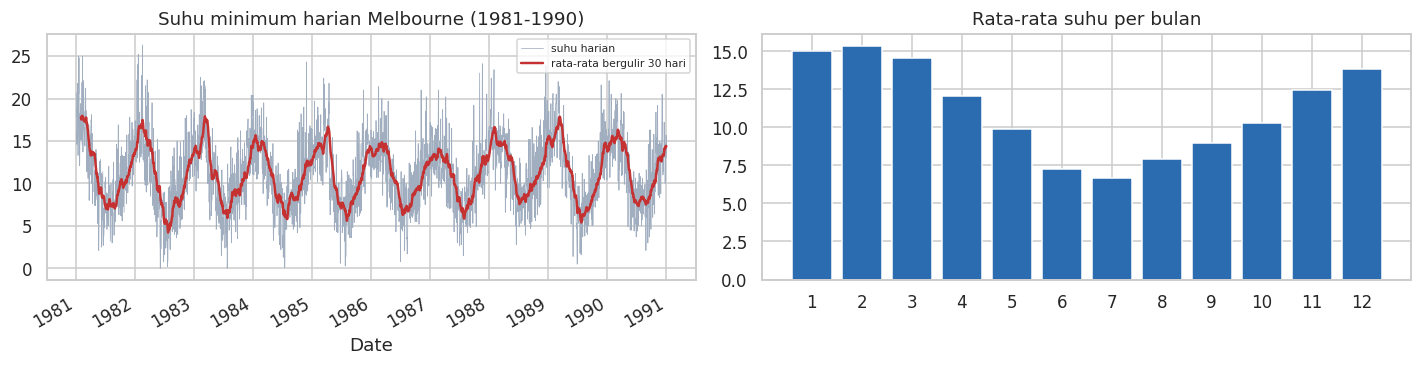

                         adf_stat   adf_p  kpss_stat  kpss_p kesimpulan
nama                                                                   
suhu (konstanta)           -4.445  0.0002      0.056     0.1  stasioner
suhu (konstanta + tren)    -4.461  0.0017      0.049     0.1  stasioner

selisih rata-rata bulan terhangat - terdingin : 8.7 derajat C
autokorelasi lag 1   : 0.775
autokorelasi lag 365 : 0.533


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
suhu_melb.plot(ax=ax[0], lw=.5, color='#a0aec0', label='suhu harian')
suhu_melb.rolling(30).mean().plot(ax=ax[0], lw=1.6, color='#c53030', label='rata-rata bergulir 30 hari')
ax[0].legend(fontsize=7); ax[0].set_title('Suhu minimum harian Melbourne (1981-1990)')
bln = suhu_melb.groupby(suhu_melb.index.month).mean()
ax[1].bar(bln.index, bln.values, color='#2b6cb0'); ax[1].set_title('Rata-rata suhu per bulan'); ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

hasil_suhu = pd.DataFrame([uji_stasioner(suhu_melb, 'suhu (konstanta)', regresi='c'),
                           uji_stasioner(suhu_melb, 'suhu (konstanta + tren)', regresi='ct')]).set_index('nama')
print(hasil_suhu)
print('\nselisih rata-rata bulan terhangat - terdingin :', round(bln.max() - bln.min(), 1), 'derajat C')
print('autokorelasi lag 1   :', round(suhu_melb.autocorr(1), 3))
print('autokorelasi lag 365 :', round(suhu_melb.autocorr(365), 3))

In [ ]:
# Menghapus pola musiman: selisih musiman lag 365 lalu uji ulang
musim_hilang = suhu_melb.diff(365).dropna()
print(pd.DataFrame([uji_stasioner(musim_hilang, 'suhu setelah diff 365')]).set_index('nama'))
print('simpangan baku sebelum -> sesudah :', round(suhu_melb.std(), 2), '->', round(musim_hilang.std(), 2))

                       adf_stat  adf_p  kpss_stat  kpss_p kesimpulan
nama                                                                
suhu setelah diff 365   -19.037    0.0      0.318     0.1  stasioner
simpangan baku sebelum -> sesudah : 4.07 -> 3.93


### Jawaban Latihan 2.3

| Uji | Statistik | p-value | Kesimpulan |
|---|---|---|---|
| ADF, konstanta | −4,445 | 0,0002 | menolak akar unit |
| KPSS, konstanta | 0,056 | 0,10 | tidak menolak stasioner |
| ADF, konstanta + tren | −4,461 | 0,0017 | menolak akar unit |
| KPSS, konstanta + tren | 0,049 | 0,10 | tidak menolak stasioner |

> **Interpretasi.** Kedua uji menyatakan suhu Melbourne **stasioner**, padahal data jelas punya pola musiman tahunan: selisih rata-rata bulan terhangat dan terdingin 8,7 °C, dan autokorelasi pada lag 365 masih 0,533. Hasil uji tidak sejalan dengan kesan visual karena ADF dan KPSS menguji akar unit dan kestabilan rata-rata jangka panjang. Pola musiman yang berulang rapi tiap tahun, tanpa tren dan tanpa guncangan permanen, tidak dianggap pelanggaran. Ini sesuai catatan di buku bahwa musiman dapat lolos sebagai stasioner.
>
> Setelah differencing musiman lag 365, uji tetap menyatakan stasioner, tetapi simpangan baku hanya turun dari 4,07 ke 3,93. Differencing menghilangkan pola musiman tetapi menggandakan varians derau acak. Pelajarannya: lolos ADF dan KPSS **tidak berarti** deret bebas pola. Musimannya tetap harus ditangani di tahap pemodelan (Bab 6 dan 7), dan pemeriksaan visual serta ACF tetap diperlukan.


## Kesimpulan

1. ADF dan KPSS dipakai berpasangan karena hipotesis nolnya berlawanan, dan hasilnya harus dibaca bersama grafik. Uji formal tidak mendeteksi varians membesar maupun musiman.
2. Inflasi bulanan Indonesia tidak punya akar unit (ADF p = 0,0235), tetapi levelnya bergeser turun sehingga KPSS menolak (p = 0,01) bila rata-rata dianggap tetap. Setelah tren dimasukkan, deret stasioner.
3. Untuk Tugas 1 dipilih **selisih biasa (d = 1)**: lolos kedua uji dengan kenaikan simpangan baku kecil (0,492 menjadi 0,537). Selisih musiman dan kombinasinya menyebabkan *over-differencing*.
4. Simulasi menunjukkan KPSS jujur (tingkat tolak 4,2% pada white noise) dengan kuasa sekitar 79,6% pada random walk (n = 100).
5. Suhu Melbourne lolos uji stasioneritas walau berpola musiman kuat, sehingga lolos uji bukan berarti deret tanpa pola.
